In [2]:
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
from matplotlib.colors import CenteredNorm, Normalize

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid, SparseGrid
from mg_sampling.density.utils import QuantileTransformation, indices_to_mask
from mg_sampling.tools import edges_to_range, bayesian_bootstrap

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Replex

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    map_ = SparseGrid.load(filename)
    vox_indices = map_.vox_indices
    map_ = map_.to_dense().apply_tempfactor(30).to_sparse(vox_indices=vox_indices)

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=map_,
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")

In [5]:
gen_map_avg = gen_maps.groupby(['sim'])[['map', 'weight']].apply(lambda x: np.average(x['map'], weights=x['weight']).to_dense())

In [19]:
def get_error(x):
    maps = np.asarray([m.data for m in x['map']])
    vox_indices = x['map'].iloc[0].vox_indices
    edges = x['map'].iloc[0].edges
    bootstrap_distribution = bayesian_bootstrap(
        maps,
        np.average,
        weights=x['weight'].to_numpy(),
        n_resamples=100,
        axis=0,
    ).bootstrap_distribution
    stderr = np.std(bootstrap_distribution, axis=0)
    stderr_map = SparseGrid(
        stderr,
        vox_indices,
        edges=edges,
    ).to_dense()
    return stderr_map

gen_map_stderr = gen_maps.groupby(['sim'])[['map', 'weight']].apply(get_error)
        

In [20]:
def plot_map_slice(
    grid: Grid,
    func: str = "imshow",
    plane="xy",
    depth=0.5,
    depth_mode="fraction",
    ax=None,
    **kwargs,
):
    if ax is None:
        ax = plt.gca()

    if isinstance(func, str):
        func = getattr(ax, func)

    x_axis, y_axis = ["xyz".index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == "fraction":
        k = int(depth * len(midpoints))
    elif depth_mode == "index":
        k = int(depth)
    elif depth_mode == "coord":
        k = int(np.searchsorted(midpoints, depth, side="left"))

    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))

    out = func(grid.grid[s].T, origin="lower", extent=extent, **kwargs)

    ax.set_xlabel("xyz"[x_axis])
    ax.set_ylabel("xyz"[y_axis])

    return out

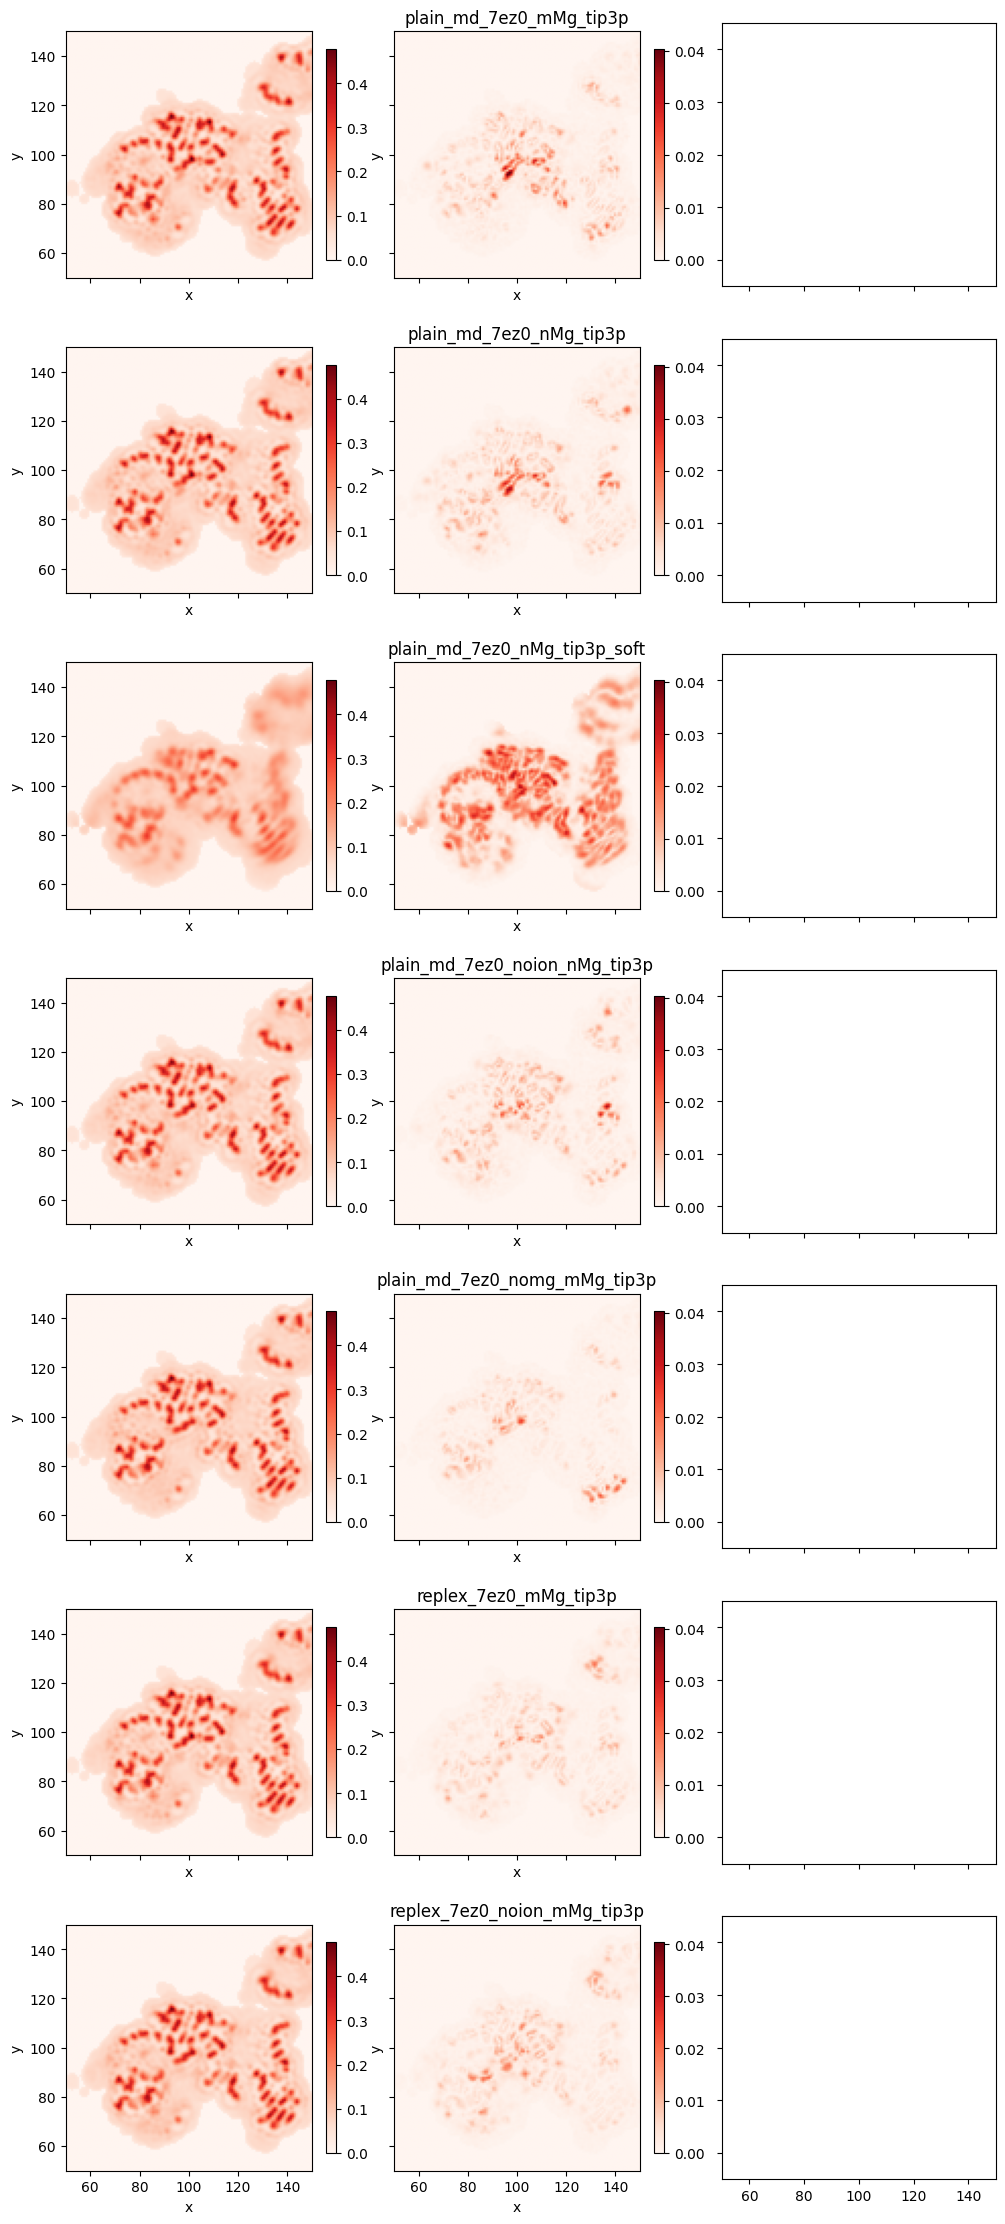

In [21]:
fig, axarr = plt.subplots(
    ncols=3, nrows=len(gen_map_avg), sharex=True, sharey=True, figsize=(12, len(gen_map_avg) * 4)
)
norm_map = Normalize()
norm_stderr = Normalize()
for v, ax in zip(gen_map_avg, axarr[:, 0]):
    _ = plot_map_slice(
        v, "imshow", ax=ax, plane='xy', norm=norm_map, cmap="Reds"
    )
for v, ax in zip(gen_map_stderr, axarr[:, 1]):
    _ = plot_map_slice(
        v, "imshow", ax=ax, plane='xy', norm=norm_stderr, cmap="Reds"
    )
plt.gca().set_xlim(50, 150)
plt.gca().set_ylim(50, 150)
for k, ax in zip(gen_map_avg.index, axarr[:, 1]):
    ax.set_title(k)
for ax in axarr[:, 0]:
    plt.colorbar(ax.images[0], ax=ax, shrink=0.8, fraction=0.05, aspect=20)
for ax in axarr[:, 1]:
    plt.colorbar(ax.images[0], ax=ax, shrink=0.8, fraction=0.05, aspect=20)

# Plot relative differences

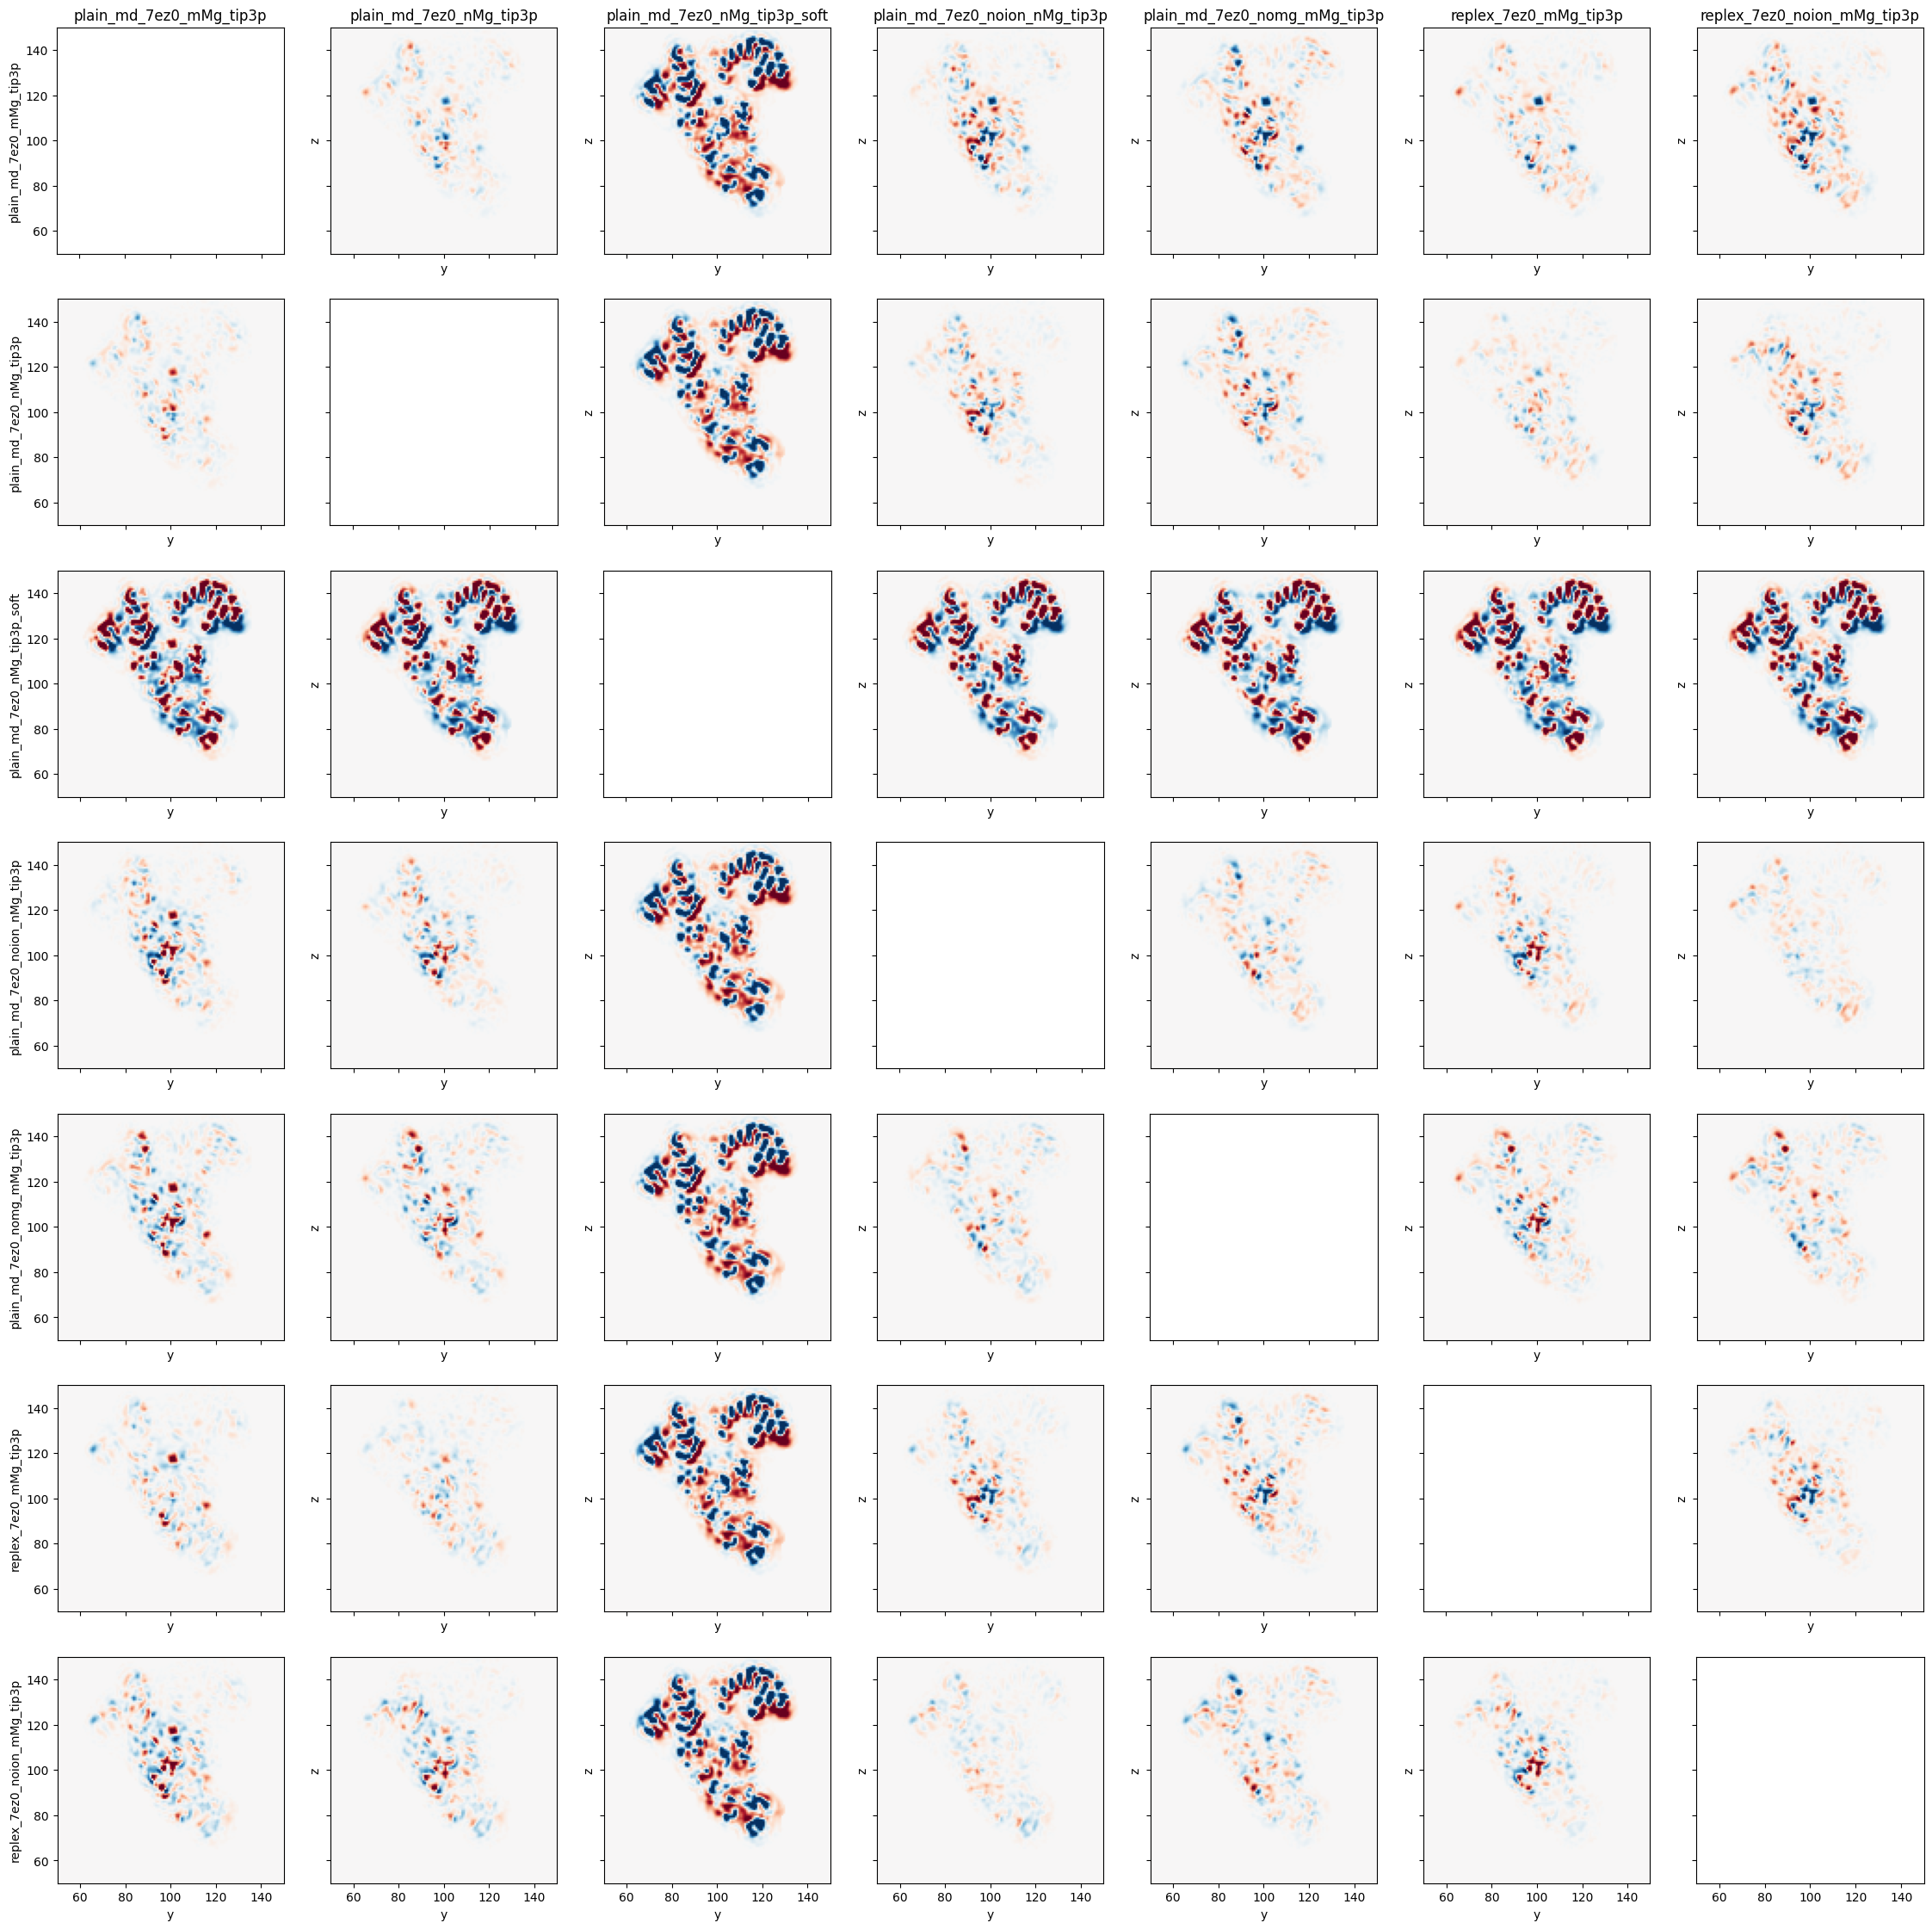

In [22]:
fig, axarr = plt.subplots(
    ncols=len(gen_map_avg), nrows=len(gen_map_avg), sharex=True, sharey=True, figsize=(len(gen_map_avg) * 4, len(gen_map_avg) * 4)
)
norm_map = CenteredNorm()
for i in range(len(gen_map_avg)):
    for j in range(len(gen_map_avg)):
        if i == j: continue
        _ = plot_map_slice(
            gen_map_avg.iloc[j] - gen_map_avg.iloc[i], "imshow", ax=axarr[i, j], plane='yz', norm=norm_map, cmap="RdBu_r"
        )
        plt.gca().set_xlim(50, 150)
        plt.gca().set_ylim(50, 150)

for k, ax in zip(gen_map_avg.index, axarr[0, :]):
    ax.set_title(k)

for k, ax in zip(gen_map_avg.index, axarr[:, 0]):
    ax.set_ylabel(k)

